# Mini-Project 2: Solar Micro-Grid Dispatch Planner

**Question.** A rural health centre in Kasese runs a micro-grid. Each day the energy from solar panels (x) and batteries (y) must meet two demands:

$$3x + 2y = D_1 \quad\text{(daytime load, kWh)} \qquad 4x + y = D_2 \quad\text{(critical-equipment load, kWh)}$$

How much does each source supply each day, which days are physically impossible, what does it cost, and how sensitive is the answer to errors in the demand figures?

**Organisation.** Reusable logic is in `src/` (`microgrid.py`, `demand.py`, `dispatch.py`, `microgrid_plotting.py`); this notebook calls it and interprets the results. It runs unattended with *Restart & Run All*: the interactive `input()` demo uses scripted answers unless you set `INTERACTIVE = True`. All randomness uses `np.random.default_rng` with fixed seeds. **All demand data are synthetic (illustrative).**

In [1]:
# Locate the repo root (the folder containing src/) so imports work wherever Jupyter was launched.
import os, sys
from pathlib import Path
for _root in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (_root / "src" / "microgrid.py").exists():
        os.chdir(_root)
        sys.path.insert(0, str(_root))
        break
else:
    raise FileNotFoundError(
        "Cannot find the 'src/' folder. Open this notebook from inside the project "
        "repository (keep src/ next to the notebook)."
    )

import timeit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.microgrid import MicroGrid, HybridMicroGrid
from src.demand import generate_demand, load_demand_csv, prompt_nonnegative_number
from src.dispatch import resolve_dispatch, source_statistics, energy_costs, sensitivity_analysis
from src.microgrid_plotting import plot_dispatch, plot_sensitivity_cloud

SEED = 42
INTERACTIVE = False      # True: the demo below asks YOU for D1 and D2 with input()
SOLAR_RATE, BATTERY_RATE = 150, 450   # illustrative UGX per kWh
pd.options.display.float_format = "{:,.2f}".format

## Task 1 — `MicroGrid` class and well-posedness

`MicroGrid` holds the coefficient matrix `A`, validates it (square, finite), exposes `solve_day(d1, d2)` and the diagnostics `determinant`, `condition_number` and `rank`. It refuses to solve a singular or badly conditioned system (`LinAlgError`) and rejects negative, empty or non-finite demands (`ValueError`).

In [2]:
grid = MicroGrid()
print(grid)
display(pd.Series(grid.diagnostics(), name="MicroGrid").to_frame())
print(f"Digits of accuracy that may be lost: about log10(cond) = {np.log10(grid.condition_number):.2f}")
print("Example: D1=100, D2=80 ->", grid.solve_day(100, 80).round(3), "(solar, battery)")

MicroGrid(sources=('solar', 'battery'), A=[[3.0, 2.0], [4.0, 1.0]])


,MicroGrid
determinant,-5.00
condition_number,5.83
rank,2
well_posed,True


Digits of accuracy that may be lost: about log10(cond) = 0.77
Example: D1=100, D2=80 -> [12. 32.] (solar, battery)


**Determinant = −5.** It is non-zero, so the two equations are independent: for *any* pair (D1, D2) there is exactly one (x, y). The sign is irrelevant; only "zero or not" matters, and the size of a determinant on its own says nothing about conditioning (it changes if you rescale the equations).

**Condition number = 5.83.** This measures how much a *relative* error in the demands can be magnified in the solution: a 1 % error in D1 and D2 can produce at most about a 5.8 % error in (x, y). That is mild, so the system is well-conditioned, and in double precision we lose less than one digit. A value near 1 would be perfectly stable, while values near 10¹² or more mean the answers cannot be trusted.

## Task 2 — Two input modes

**(a) Interactive `input()`** — `prompt_nonnegative_number` rejects empty, non-numeric, `nan`/`inf` and negative entries and asks again. So that the notebook can run unattended, the demo below feeds it scripted answers that exercise every rejection path. Set `INTERACTIVE = True` in the setup cell to type values yourself.

In [3]:
def ask(prompt, scripted):
    if INTERACTIVE:
        return prompt_nonnegative_number(prompt)
    answers = iter(scripted)
    def fake_input(p):
        reply = next(answers)
        print(f"{p}{reply!r}")
        return reply
    return prompt_nonnegative_number(prompt, input_fn=fake_input)

d1 = ask("Enter D1 (daytime load, kWh): ", ["", "abc", "-5", "nan", "57"])
d2 = ask("Enter D2 (critical-equipment load, kWh): ", ["inf", "66"])
x, y = grid.solve_day(d1, d2)
print(f"\nSolved: solar x = {x:.2f} kWh, battery y = {y:.2f} kWh")

Enter D1 (daytime load, kWh): ''
Value cannot be empty. Try again.
Enter D1 (daytime load, kWh): 'abc'
'abc' is not a number. Try again.
Enter D1 (daytime load, kWh): '-5'
Value cannot be negative. Try again.
Enter D1 (daytime load, kWh): 'nan'
Value must be finite. Try again.
Enter D1 (daytime load, kWh): '57'
Enter D2 (critical-equipment load, kWh): 'inf'
Value must be finite. Try again.
Enter D2 (critical-equipment load, kWh): '66'

Solved: solar x = 15.00 kWh, battery y = 6.00 kWh


**(b) CSV mode.** 30 days of demand are generated with a seeded `default_rng(42)` and saved to `data/microgrid_demand_30days.csv`, then loaded back through `load_demand_csv` (which validates columns, numeric values, negatives and empty files).

*Weekly pattern (my assumption, illustrative).* The clinic is busy on weekdays (daytime load D1 ≈ 70–74 kWh) and quiet at weekends (≈ 54 kWh Saturday, ≈ 47 kWh Sunday). Critical equipment such as refrigeration and oxygen runs all week (D2 ≈ 65–69 kWh). Noise: N(0, 3.5) on D1 and N(0, 2.5) on D2.

In [4]:
os.makedirs("data", exist_ok=True)
CSV_PATH = "data/microgrid_demand_30days.csv"
generate_demand(n_days=30, seed=SEED).to_csv(CSV_PATH, index=False)

demand_df, B = load_demand_csv(CSV_PATH)      # B has shape (2, 30): rows D1, D2
demand_df["weekday"] = pd.to_datetime(demand_df["date"]).dt.day_name().str[:3]
display(demand_df.head(8))
print("B shape:", B.shape)
display(demand_df.groupby("weekday")[["D1_kWh", "D2_kWh"]].mean().reindex(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).round(1).T)

,date,D1_kWh,D2_kWh,weekday
0,2026-01-05,73.07,73.35,Mon
1,2026-01-06,70.36,67.98,Tue
2,2026-01-07,75.63,66.72,Wed
3,2026-01-08,75.29,65.97,Thu
4,2026-01-09,63.17,68.54,Fri
5,2026-01-10,49.44,68.82,Sat
6,2026-01-11,47.45,64.72,Sun
7,2026-01-12,70.89,65.90,Mon


B shape: (2, 30)


weekday,Mon,Tue,Wed,Thu,Fri,Sat,Sun
D1_kWh,72.10,73.80,73.10,72.40,69.40,53.30,48.30
D2_kWh,68.60,68.20,68.40,67.80,67.80,66.20,66.20


## Task 3 — 30 days: Python loop vs one vectorised call

`solve_loop` calls `scipy.linalg.solve` once per day; `solve_batch` passes the whole 2 × 30 right-hand side in a single call. Timing uses `timeit.repeat` and takes the fastest of five runs (the least disturbed by other processes).

In [5]:
loop_sol, vec_sol = grid.solve_loop(B), grid.solve_batch(B)
print("Same answers:", np.allclose(loop_sol, vec_sol), "| shape:", vec_sol.shape)

N = 1000
t_loop  = min(timeit.repeat(lambda: grid.solve_loop(B),  number=N, repeat=5))
t_batch = min(timeit.repeat(lambda: grid.solve_batch(B), number=N, repeat=5))
print(f"Loop:       {t_loop / N * 1e6:8.1f} microseconds per 30-day solve")
print(f"Vectorised: {t_batch / N * 1e6:8.1f} microseconds per 30-day solve")
print(f"Loop is {t_loop / t_batch:.1f}x slower")

Same answers: True | shape: (2, 30)


Loop:          946.2 microseconds per 30-day solve
Vectorised:     82.4 microseconds per 30-day solve
Loop is 11.5x slower


The vectorised call is roughly **an order of magnitude faster** (about 10–15× on my machine; the exact ratio varies with hardware). The matrix `A` is the same every day, so one call can factorise it (LU) **once** and back-substitute for all 30 columns, whereas the loop repeats the factorisation, the input checks and the Python call overhead 30 times. The gap would grow with more days or a larger system, and for tiny problems both are fast enough that clarity matters more than speed.

## Task 4 — Infeasible days

A negative x or y is physically impossible (a source cannot supply negative energy). Solving the system exactly gives
$x = (2D_2 - D_1)/5$ and $y = (4D_1 - 3D_2)/5$, so **a day is feasible only if $0.75\,D_2 \le D_1 \le 2\,D_2$**. On quiet weekends D1 falls well below D2, so y can go negative.

Strategy: `resolve_dispatch` flags such days and repairs them with **non-negative least squares** (`scipy.optimize.nnls`): the non-negative (x, y) that gets as close as possible to satisfying both equations. For comparison it also supports simple **clipping** (set the negative value to zero and keep the other).

In [6]:
res = resolve_dispatch(grid, B, strategy="nnls")
clip = resolve_dispatch(grid, B, strategy="clip")
print(f"Infeasible days: {res.n_infeasible} of {B.shape[1]}")

bad = np.flatnonzero(res.infeasible)
report = pd.DataFrame({
    "day": bad + 1,
    "date": demand_df.loc[bad, "date"].values,
    "weekday": demand_df.loc[bad, "weekday"].values,
    "D1/D2": (B[0, bad] / B[1, bad]).round(3),
    "exact x": res.raw[0, bad], "exact y": res.raw[1, bad],
    "NNLS x": res.dispatch[0, bad], "NNLS y": res.dispatch[1, bad],
    "NNLS residual (kWh)": res.residual_norm[bad],
    "clip residual (kWh)": clip.residual_norm[bad],
    "NNLS residual / demand (%)": res.residual_norm[bad] / np.linalg.norm(B[:, bad], axis=0) * 100,
}).set_index("day")
display(report)
print(f"Total load mismatch over the month: NNLS = {res.residual_norm.sum():.2f} kWh, clipping = {clip.residual_norm.sum():.2f} kWh")
print("All final values non-negative:", bool((res.dispatch >= 0).all()))

Infeasible days: 4 of 30


,date,weekday,D1/D2,exact x,exact y,NNLS x,NNLS y,NNLS residual (kWh),clip residual (kWh),NNLS residual / demand (%)
day,,,,,,,,,,
6,2026-01-10,Sat,0.72,17.64,-1.74,16.94,0.00,1.74,3.89,2.05
7,2026-01-11,Sun,0.73,16.40,-0.87,16.05,0.00,0.87,1.95,1.09
21,2026-01-25,Sun,0.70,17.02,-2.35,16.08,0.00,2.35,5.26,2.92
28,2026-02-01,Sun,0.70,17.84,-2.62,16.79,0.00,2.62,5.86,3.12


Total load mismatch over the month: NNLS = 7.58 kWh, clipping = 16.96 kWh
All final values non-negative: True


Four days are infeasible, all quiet weekend days (days 6, 7, 21 and 28), where D1/D2 drops below the 0.75 threshold. Physically, the critical equipment needs more energy than the daytime-load equation allows the battery to supply, so the exact answer would require the battery to *absorb* energy.

**Trade-off.** Neither repair satisfies both equations: that is impossible. NNLS leaves the smaller mismatch (0.9–2.6 kWh a day, about 1–3 % of that day's demand, 7.6 kWh over the month) than clipping (17.0 kWh) because it re-optimises x instead of only zeroing y. The unmet or over-supplied energy would in practice have to come from another source, which is exactly the role of the diesel generator in the hybrid extension.

## Task 5 — Volatility of solar and battery use

In [7]:
rows = {name: source_statistics(res.dispatch[i]) for i, name in enumerate(["Solar x", "Battery y"])}
stats_df = pd.DataFrame(rows).T.rename(columns={"mean": "mean (kWh)", "variance": "variance (kWh²)",
                                                "stdev": "st. dev. (kWh)", "cv_percent": "CV (%)"})
display(stats_df)

,mean (kWh),variance (kWh²),st. dev. (kWh),CV (%)
Solar x,13.65,2.91,1.71,12.50
Battery y,12.88,52.96,7.28,56.49


**The battery is the more volatile source on both measures**: standard deviation 7.3 vs 1.7 kWh and coefficient of variation 56 % vs 12.5 %. (Both sources are in kWh, so st. dev. is comparable here, but the CV is safer because the sources have different means.)

The reason is structural: $y = (4D_1 - 3D_2)/5$ responds strongly to D1, which swings with the weekly clinic pattern, while $x = (2D_2 - D_1)/5$ depends mostly on the steadier D2. The battery therefore absorbs most of the weekday/weekend swing. The mean is taken over the repaired values (floored at zero on infeasible days), which slightly lowers battery variance compared with the unconstrained solution.

## Task 6 — Cost model

Illustrative tariffs: solar **UGX 150/kWh**, battery **UGX 450/kWh**.

In [8]:
cost = energy_costs(res.dispatch[0], res.dispatch[1], SOLAR_RATE, BATTERY_RATE)
energy = {"Solar": res.dispatch[0].sum(), "Battery": res.dispatch[1].sum()}
summary = pd.DataFrame({
    "Energy (kWh)": energy,
    "Cost (UGX)": {"Solar": cost["solar_total"], "Battery": cost["battery_total"]},
})
summary["Share of energy (%)"] = summary["Energy (kWh)"] / summary["Energy (kWh)"].sum() * 100
summary["Share of cost (%)"] = summary["Cost (UGX)"] / summary["Cost (UGX)"].sum() * 100
display(summary.style.format("{:,.1f}"))
print(f"Monthly total cost: UGX {cost['monthly_total']:,.0f}")
print(f"Average daily cost: UGX {cost['daily'].mean():,.0f} (min {cost['daily'].min():,.0f}, max {cost['daily'].max():,.0f})")

,Energy (kWh),Cost (UGX),Share of energy (%),Share of cost (%)
Solar,409.6,"61,445.2",51.5,26.1
Battery,386.5,"173,907.9",48.5,73.9


Monthly total cost: UGX 235,353
Average daily cost: UGX 7,845 (min 2,407, max 12,107)


The monthly bill is **UGX 235,353** (about 7,845 a day). The battery supplies about 49 % of the energy but accounts for **74 %** of the cost because it is three times as expensive per kWh, so any plan to cut costs should target battery use first. On repaired days the cost covers only the energy actually dispatched, so it understates the true cost of meeting the load.

## Task 7 — Stacked bars with daily cost

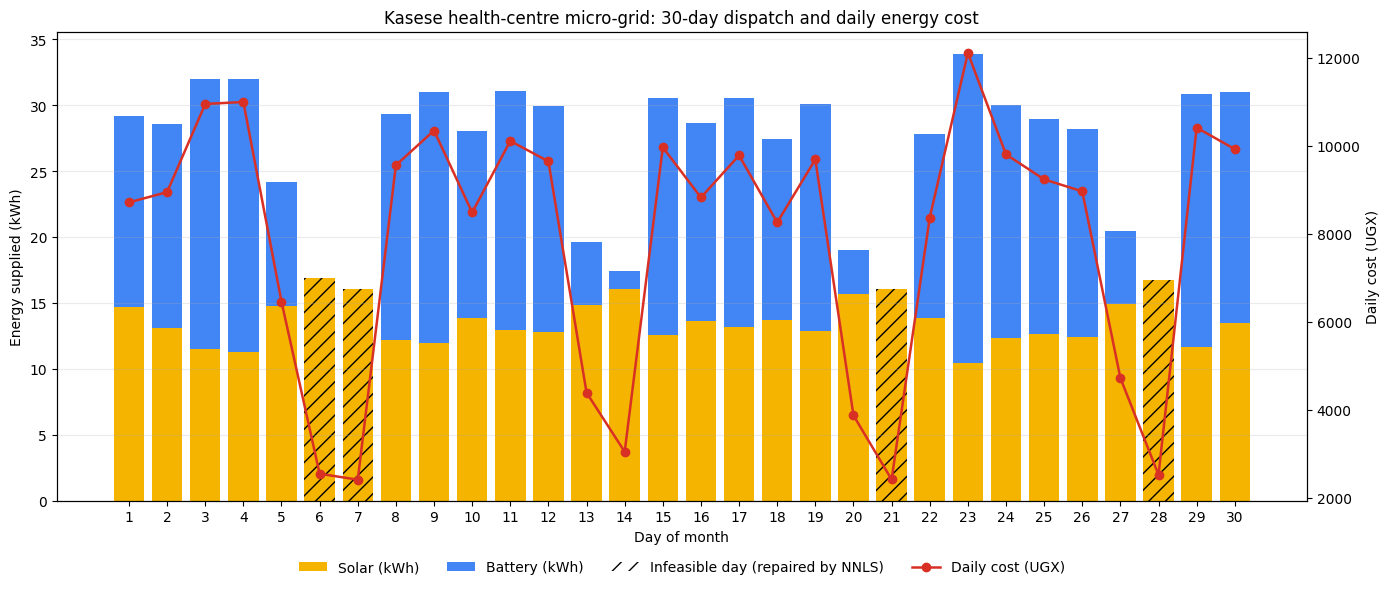

In [9]:
os.makedirs("figures", exist_ok=True)
fig = plot_dispatch(res.dispatch[0], res.dispatch[1], cost["daily"], infeasible=res.infeasible)
fig.savefig("figures/microgrid_dispatch.png", dpi=150, bbox_inches="tight")
plt.show()

The cost line mirrors the *battery* share of each bar, not the bar height: the quiet weekend days (hatched = repaired) have the cheapest bills because the battery supplies little or nothing, while busy weekdays cost more as battery use rises.

## Extension A — `HybridMicroGrid` with a diesel generator

`HybridMicroGrid(MicroGrid)` adds diesel `z` and a third equation. My choice is a total-generation balance $x + y + z = D_3$, giving a 3 × 3 system. It reuses the parent's validation and diagnostics through `super().__init__`, and only adds the third row.

In [10]:
hybrid = HybridMicroGrid()
print("Well-posed hybrid:", hybrid.diagnostics())
print("D1=54, D2=62, D3=23 ->", dict(zip(hybrid.source_names, hybrid.solve_day(54, 62, 23).round(3))))

# Third equation dependent on the first two: row3 = row1 + row2 and no diesel term
dep = HybridMicroGrid(third_row=(7, 3, 0))
print("\nDependent system:", dep.diagnostics())
A_aug = np.column_stack([dep.A, [100, 80, 180]])
print("rank(A) =", dep.rank, "| rank([A|b]) =", np.linalg.matrix_rank(A_aug), "| unknowns = 3")
try:
    dep.solve_day(100, 80, 180)
except np.linalg.LinAlgError as e:
    print("solve_day refused:", e)

Well-posed hybrid: {'determinant': -4.999999999999999, 'condition_number': 7.715758300081699, 'rank': 3, 'well_posed': True}
D1=54, D2=62, D3=23 -> {'solar': np.float64(14.0), 'battery': np.float64(6.0), 'diesel': np.float64(3.0)}

Dependent system: {'determinant': 0.0, 'condition_number': inf, 'rank': 2, 'well_posed': False}
rank(A) = 2 | rank([A|b]) = 2 | unknowns = 3
solve_day refused: System is singular (linearly dependent equations) or too ill-conditioned to solve reliably.


With a sensible third equation the 3 × 3 system is well-posed (condition number 7.7, a little worse than the 2 × 2 case) and gives a unique (solar, battery, diesel).

If the new equation is **linearly dependent** on the others (here row 3 = row 1 + row 2), the rank drops to 2 < 3, the determinant is 0 and the condition number is infinite. Then:

- if the right-hand side is consistent (as for D3 = D1 + D2 = 180), the rank of the augmented matrix is also 2, so there are **infinitely many solutions**: nothing determines diesel `z` at all;
- if it is inconsistent, there is **no solution**.

Either way a unique dispatch does not exist, so the class refuses to solve rather than return a meaningless number. The fix is a genuinely new piece of information, such as a diesel fuel budget or a minimum-cost objective.

## Extension B — Sensitivity to ±5 % demand error (Monte Carlo)

Every demand (both loads, all 30 days) is perturbed by an independent uniform ±5 % in **1,000 draws**, and all 30,000 systems are re-solved in one vectorised call. The baseline is the exact (unrepaired) solution.

,mean move (kWh),95th pct move (kWh),mean source use (kWh),mean move as % of mean use
Solar x,0.73,1.59,13.76,5.31
Battery y,1.60,3.69,13.13,12.15


Amplification of relative error (output change / input change): mean = 3.35, max = 5.824
Condition number (theoretical worst case): 5.828


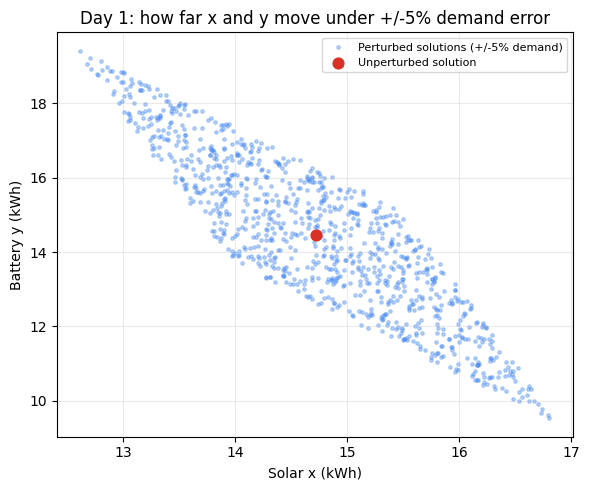

In [11]:
sens = sensitivity_analysis(grid, B, pct=0.05, n_draws=1000, seed=2026)
moves = pd.DataFrame({"mean move (kWh)": sens.mean_move, "95th pct move (kWh)": sens.p95_move,
                      "mean source use (kWh)": np.abs(sens.baseline).mean(axis=1)},
                     index=["Solar x", "Battery y"])
moves["mean move as % of mean use"] = moves["mean move (kWh)"] / moves["mean source use (kWh)"] * 100
display(moves)
print(f"Amplification of relative error (output change / input change): "
      f"mean = {sens.amplification_mean:.2f}, max = {sens.amplification_max:.3f}")
print(f"Condition number (theoretical worst case): {sens.condition_number:.3f}")
assert sens.amplification_max <= sens.condition_number + 1e-9
plot_sensitivity_cloud(sens.draws, sens.baseline, day=0)
plt.show()

A ±5 % error in the demand figures moves solar by about **0.7 kWh** and battery by about **1.6 kWh** on average (95th percentile 1.6 and 3.7 kWh). In relative terms that is a large effect for the battery, because its typical use is small. The average amplification of relative error is about 3.4×, and the largest observed is **5.82 against the condition number 5.83**: the condition number is a true worst-case bound that is almost reached when the errors line up with the matrix's most sensitive direction. The elongated cloud in the plot shows that direction: the errors in x and y are strongly *negatively* correlated (when solar is over-estimated, battery is under-estimated), so some combinations of demand error matter far more than others.

## Sanity checks (second method / hand calculation)

In [12]:
# 1. Closed-form solution from the algebra above vs scipy
x_hand = (2 * B[1] - B[0]) / 5
y_hand = (4 * B[0] - 3 * B[1]) / 5
assert np.allclose(res.raw[0], x_hand) and np.allclose(res.raw[1], y_hand)

# 2. The exact solution really satisfies both equations on every day
assert np.allclose(3 * res.raw[0] + 2 * res.raw[1], B[0])
assert np.allclose(4 * res.raw[0] + res.raw[1], B[1])

# 3. Feasibility rule 0.75*D2 <= D1 <= 2*D2 predicts exactly the flagged days
rule_infeasible = (B[0] < 0.75 * B[1]) | (B[0] > 2 * B[1])
assert np.array_equal(rule_infeasible, res.infeasible)

# 4. Day-1 cost by hand
assert np.isclose(cost["daily"][0], 150 * res.dispatch[0, 0] + 450 * res.dispatch[1, 0])
print("All sanity checks passed.")

All sanity checks passed.


## Findings & Limitations

**Findings.** The system is well-posed (determinant −5, condition number 5.83), so every demand pair has a unique solution and demand errors are magnified at most 5.8×. Solving 30 days in one vectorised call is about 10–15× faster than a Python loop. Solving exactly gave a negative battery value on four quiet weekend days (6, 7, 21, 28), where D1 fell below 75 % of D2; non-negative least squares repaired them with a 0.9–2.6 kWh load mismatch per day (7.6 kWh in total, against 17.0 kWh for clipping). Battery use is far more volatile than solar (st. dev. 7.3 vs 1.7 kWh; CV 56 % vs 12.5 %) because it absorbs the weekly swing in D1, and it drives cost: 74 % of the UGX 235,353 monthly bill for about 49 % of the energy. A ±5 % demand error moves solar by roughly 0.7 kWh and battery by 1.6 kWh, an amplification of 3.4× on average and up to 5.8×, as the condition number predicts.

**Limitations.** Demand is synthetic, and I chose the weekend pattern, so the number of infeasible days is an artefact of my assumptions. The model has no battery state of charge, storage limits or solar profile, so the repair leaves some load unserved rather than modelling diesel backup. Tariffs are flat and illustrative. The Monte Carlo assumes independent uniform errors; correlated sensor errors would behave differently. The hybrid third equation (total generation) is my own assumption.